In [1]:
# 1. Libraries
import pandas as pd
from sklearn.model_selection import train_test_split

# 2. Load the synthetic dataset
df = pd.read_csv("../data/synthetic_pain_patients.csv")

# 3. Safety gate: patients with red flags are referred, not classified
df_model = df[~df["any_red_flag"]].copy()

print("All patients:", len(df))
print("Excluded (red flags):", df["any_red_flag"].sum())
print("Eligible for the model:", len(df_model))

# 4. Features (X) and target (y)
NUMERIC_FEATURES = [
    "pain_duration_months", "dn4_score", "paindetect_score", "csi_score",
    "sleep_quality", "hads_anxiety", "hads_depression", "pcs_score",
    "tsk_score", "work_stress",
]
CATEGORICAL_FEATURES = ["pain_distribution", "imaging_tissue_finding", "imaging_nerve_compression"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "mechanism"

X = df_model[FEATURES]
y = df_model[TARGET]

# 5. Train/test split (80/20, stratified by mechanism)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

All patients: 2000
Excluded (red flags): 190
Eligible for the model: 1810
Train: (1448, 13) | Test: (362, 13)


In [2]:
# Check: class proportions in train and test
pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).round(3)

,train,test
mechanism,,
nociceptive,0.394,0.395
mixed,0.264,0.262
nociplastic,0.190,0.191
neuropathic,0.152,0.152


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# Build the preprocessing pipeline (with or without missing indicators)
def make_preprocessor(add_missing_indicator):
    numeric_steps = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=add_missing_indicator)),
        ("scale", StandardScaler()),
    ])
    categorical_steps = OneHotEncoder(handle_unknown="ignore")

    return ColumnTransformer([
        ("num", numeric_steps, NUMERIC_FEATURES),
        ("cat", categorical_steps, CATEGORICAL_FEATURES),
    ])


preprocessor_plain = make_preprocessor(add_missing_indicator=False)
preprocessor_indicator = make_preprocessor(add_missing_indicator=True)

# Learn imputation, scaling and encoding from the TRAINING data only
X_train_plain = preprocessor_plain.fit_transform(X_train)
X_train_indicator = preprocessor_indicator.fit_transform(X_train)

print("Without missing indicators:", X_train_plain.shape)
print("With missing indicators:   ", X_train_indicator.shape)

Without missing indicators: (1448, 20)
With missing indicators:    (1448, 27)


In [4]:
# Names of the columns created by the preprocessing
list(preprocessor_indicator.get_feature_names_out())

['num__pain_duration_months',
 'num__dn4_score',
 'num__paindetect_score',
 'num__csi_score',
 'num__sleep_quality',
 'num__hads_anxiety',
 'num__hads_depression',
 'num__pcs_score',
 'num__tsk_score',
 'num__work_stress',
 'num__missingindicator_dn4_score',
 'num__missingindicator_paindetect_score',
 'num__missingindicator_csi_score',
 'num__missingindicator_hads_anxiety',
 'num__missingindicator_hads_depression',
 'num__missingindicator_pcs_score',
 'num__missingindicator_tsk_score',
 'cat__pain_distribution_dermatomal',
 'cat__pain_distribution_localized',
 'cat__pain_distribution_regional',
 'cat__pain_distribution_widespread',
 'cat__imaging_tissue_finding_no',
 'cat__imaging_tissue_finding_not_performed',
 'cat__imaging_tissue_finding_yes',
 'cat__imaging_nerve_compression_no',
 'cat__imaging_nerve_compression_not_performed',
 'cat__imaging_nerve_compression_yes']

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Candidate models
models = {
    "Logistic regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
}

# 5-fold stratified cross-validation and metrics
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["balanced_accuracy", "f1_macro", "roc_auc_ovr"]

# Train and evaluate every model, with and without missing indicators
results = []

for model_name, model in models.items():
    for indicator in [False, True]:
        pipeline = Pipeline([
            ("preprocess", make_preprocessor(add_missing_indicator=indicator)),
            ("model", model),
        ])
        scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)

        results.append({
            "model": model_name,
            "missing_indicator": indicator,
            "balanced_accuracy": scores["test_balanced_accuracy"].mean(),
            "f1_macro": scores["test_f1_macro"].mean(),
            "auroc": scores["test_roc_auc_ovr"].mean(),
            "auroc_std": scores["test_roc_auc_ovr"].std(),
        })

pd.DataFrame(results).round(3)

,model,missing_indicator,balanced_accuracy,f1_macro,auroc,auroc_std
0,Logistic regression,False,0.796,0.783,0.953,0.007
1,Logistic regression,True,0.783,0.771,0.952,0.006
2,Random forest,False,0.802,0.795,0.949,0.010
3,Random forest,True,0.802,0.796,0.950,0.009


In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    balanced_accuracy_score, roc_auc_score, classification_report, ConfusionMatrixDisplay,
)

MECHANISM_ORDER = ["nociceptive", "neuropathic", "mixed", "nociplastic"]

# Final model: logistic regression without missing indicators
final_model = Pipeline([
    ("preprocess", make_preprocessor(add_missing_indicator=False)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

# Train on the full training set
final_model.fit(X_train, y_train)

# Open the test set (only once)
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)

print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 3))
print("AUROC (one-vs-rest):", round(roc_auc_score(y_test, y_proba, multi_class="ovr"), 3))
print()
print(classification_report(y_test, y_pred, labels=MECHANISM_ORDER, digits=3))

Balanced accuracy: 0.805
AUROC (one-vs-rest): 0.96

              precision    recall  f1-score   support

 nociceptive      0.953     0.986     0.969       143
 neuropathic      0.762     0.873     0.814        55
       mixed      0.694     0.621     0.656        95
 nociplastic      0.773     0.739     0.756        69

    accuracy                          0.826       362
   macro avg      0.795     0.805     0.798       362
weighted avg      0.822     0.826     0.822       362



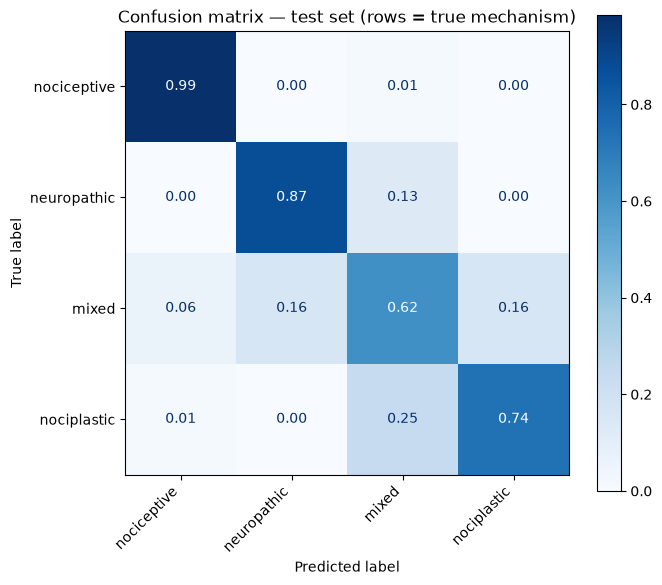

In [7]:
# Confusion matrix on the test set (each row sums to 1)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=MECHANISM_ORDER, normalize="true",
    cmap="Blues", values_format=".2f", ax=ax,
)
ax.set_title("Confusion matrix — test set (rows = true mechanism)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Scenario B: specialised chronic pain clinic (from the criteria document)
SCENARIO_B = {"nociceptive": 0.20, "neuropathic": 0.10, "mixed": 0.30, "nociplastic": 0.40}
N_B = 2000

# Resample test patients (with replacement) to match the scenario B case mix
rng_b = np.random.default_rng(seed=7)
test_df = X_test.copy()
test_df["mechanism"] = y_test

parts = []
for mechanism, share in SCENARIO_B.items():
    pool = test_df[test_df["mechanism"] == mechanism]
    chosen = rng_b.choice(pool.index, size=int(share * N_B), replace=True)
    parts.append(pool.loc[chosen])

scenario_b = pd.concat(parts)
X_b = scenario_b[FEATURES]
y_b = scenario_b["mechanism"]
y_pred_b = final_model.predict(X_b)


# Per-class precision and recall
def per_class(y_true, y_hat):
    return pd.DataFrame({
        "precision": precision_score(y_true, y_hat, labels=MECHANISM_ORDER, average=None),
        "recall": recall_score(y_true, y_hat, labels=MECHANISM_ORDER, average=None),
    }, index=MECHANISM_ORDER)


print("Scenario A — accuracy:", round(accuracy_score(y_test, y_pred), 3),
      "| balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 3))
print("Scenario B — accuracy:", round(accuracy_score(y_b, y_pred_b), 3),
      "| balanced accuracy:", round(balanced_accuracy_score(y_b, y_pred_b), 3))

pd.concat({"Scenario A": per_class(y_test, y_pred), "Scenario B": per_class(y_b, y_pred_b)}, axis=1).round(3)

Scenario A — accuracy: 0.826 | balanced accuracy: 0.805
Scenario B — accuracy: 0.769 | balanced accuracy: 0.811


Scenario A        Scenario B       
             precision recall  precision recall
nociceptive      0.953  0.986      0.891  0.982
neuropathic      0.762  0.873      0.650  0.890
mixed            0.694  0.621      0.625  0.648
nociplastic      0.773  0.739      0.873  0.724

In [9]:
# Test 1 — Ablation: retrain the model without imaging variables
NO_IMAGING_FEATURES = NUMERIC_FEATURES + ["pain_distribution"]

no_imaging_preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["pain_distribution"]),
])
model_no_imaging = Pipeline([
    ("preprocess", no_imaging_preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
model_no_imaging.fit(X_train[NO_IMAGING_FEATURES], y_train)
y_pred_no_imaging = model_no_imaging.predict(X_test[NO_IMAGING_FEATURES])

# Test 2 — Workflow change: final model used where nobody had imaging
X_test_no_exams = X_test.copy()
X_test_no_exams[["imaging_tissue_finding", "imaging_nerve_compression"]] = "not_performed"
y_pred_no_exams = final_model.predict(X_test_no_exams)

# Compare recall per mechanism and balanced accuracy
predictions = {
    "Final model": y_pred,
    "Retrained without imaging": y_pred_no_imaging,
    "Final model, no exams done": y_pred_no_exams,
}

summary = pd.DataFrame({name: per_class(y_test, p)["recall"] for name, p in predictions.items()})
summary.loc["balanced_accuracy"] = [balanced_accuracy_score(y_test, p) for p in predictions.values()]
summary.round(3)

,Final model,Retrained without imaging,"Final model, no exams done"
nociceptive,0.986,0.986,0.986
neuropathic,0.873,0.800,0.764
mixed,0.621,0.611,0.642
nociplastic,0.739,0.725,0.725
balanced_accuracy,0.805,0.780,0.779


In [10]:
# Harmful error: nociplastic patients classified as nociceptive
for name, p in predictions.items():
    harmful = ((y_test == "nociplastic") & (p == "nociceptive")).sum()
    print(f"{name}: {harmful} of {(y_test == 'nociplastic').sum()} nociplastic patients")

Final model: 1 of 69 nociplastic patients
Retrained without imaging: 1 of 69 nociplastic patients
Final model, no exams done: 2 of 69 nociplastic patients


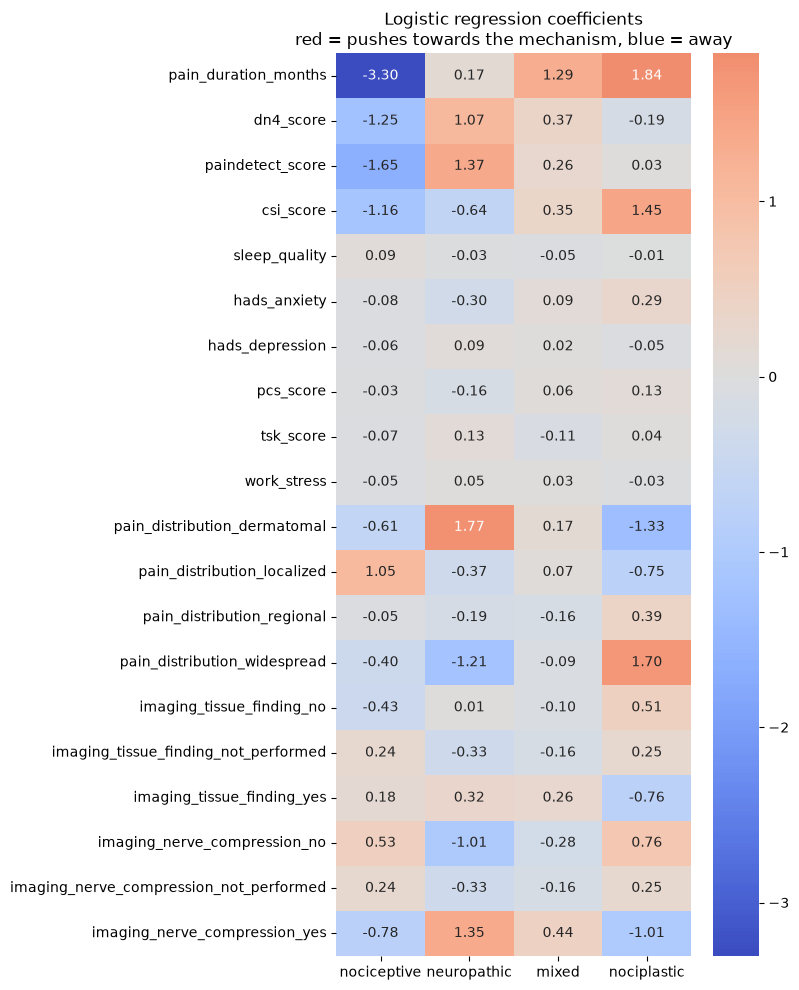

In [11]:
import seaborn as sns

# Pieces of the trained pipeline
preprocess_step = final_model.named_steps["preprocess"]
model_step = final_model.named_steps["model"]

# Coefficients: one row per mechanism, one column per feature
coef_table = pd.DataFrame(
    model_step.coef_,
    index=model_step.classes_,
    columns=preprocess_step.get_feature_names_out(),
)

# Cleaner names, clinical order, one row per feature
coef_table.columns = coef_table.columns.str.replace("num__", "").str.replace("cat__", "")
coef_table = coef_table.loc[MECHANISM_ORDER].T

# Heatmap
fig, ax = plt.subplots(figsize=(8, 10))
sns.heatmap(coef_table, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Logistic regression coefficients\nred = pushes towards the mechanism, blue = away")
plt.tight_layout()
plt.show()

c:\Users\Renato\Desktop\PROJETOS\pain-mechanism-classifier\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 1448 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1448 when initializing the masker.


True mechanism: nociplastic
Predicted: mixed
Probabilities: {'mixed': 0.54, 'neuropathic': 0.01, 'nociceptive': 0.0, 'nociplastic': 0.46}


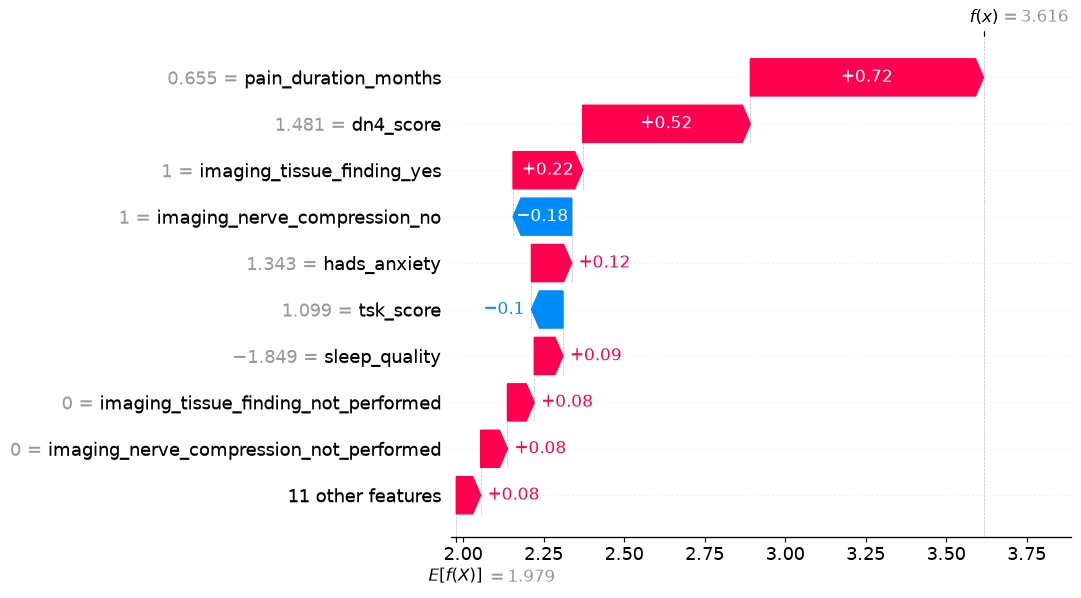

In [12]:
import shap

# Transform the data with the trained preprocessing
X_train_t = preprocess_step.transform(X_train)
X_test_t = preprocess_step.transform(X_test)

# SHAP explainer for a linear model (training data as reference)
explainer = shap.LinearExplainer(model_step, X_train_t)
shap_values = explainer(X_test_t)
shap_values.feature_names = coef_table.index.tolist()

# Pick one test patient: the first true nociplastic case
patient_pos = np.where(y_test.values == "nociplastic")[0][0]
predicted = y_pred[patient_pos]
class_pos = list(model_step.classes_).index(predicted)

print("True mechanism:", y_test.iloc[patient_pos])
print("Predicted:", predicted)
print("Probabilities:", {c: round(float(p), 2) for c, p in zip(model_step.classes_, y_proba[patient_pos])})

# Waterfall: which features pushed this patient towards the predicted mechanism
shap.plots.waterfall(shap_values[patient_pos, :, class_pos], max_display=10)

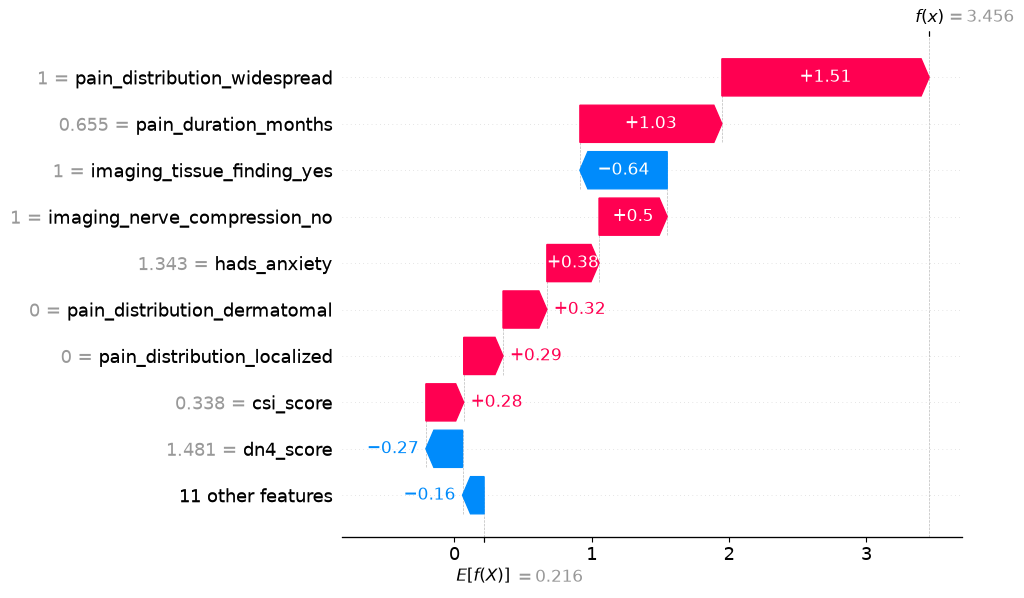

In [13]:
# Same patient, explanation for the nociplastic class
nociplastic_pos = list(model_step.classes_).index("nociplastic")
shap.plots.waterfall(shap_values[patient_pos, :, nociplastic_pos], max_display=10)

In [14]:
import joblib
from pathlib import Path

# Folder for the trained model
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

# Save the final pipeline (preprocessing + logistic regression)
MODEL_PATH = MODEL_DIR / "pain_mechanism_model.joblib"
joblib.dump(final_model, MODEL_PATH)

# Check: reload and compare predictions
loaded_model = joblib.load(MODEL_PATH)
print("Saved to:", MODEL_PATH)
print("Same predictions after reload:", (loaded_model.predict(X_test) == y_pred).all())

Saved to: ..\models\pain_mechanism_model.joblib
Same predictions after reload: True
